# Prova Aprendizado supervisionado

Este notebook é o documento utilizado na cadeira de Aprendizado Supervisonado, administrado pelo professor Alexandre.

## Introdução

Para esta atividade irei implementar o modelo de classificação Logistic Regression manualmente e comparar os resultados com o modelo implementado pela biblioteca scikit-learn.

### Bibliotecas utilizadas

In [5]:
import pandas as pd
import numpy as np
import math

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



import matplotlib.pyplot as plt
import seaborn as sns


## 1 - Conhecendo os dados

Foram utilizado os dados provinientes do link do kaggle [Grade Prediction Based on Socioeconomics Factors](https://www.kaggle.com/datasets/chaitanyajamble/grade-prediction-based-on-socioeconomic-factors) e estão armazenos na pasta `data` deste repositório . 

Segue uma breve análise dos dados:



In [6]:


df_original = pd.read_csv('data/student_grade_ses_dataset.csv')

df = df_original.copy()

del df_original

display(df.head())
display(df.info())
display(df.columns)


,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

None

Index(['student_id', 'academic_year', 'survey_date', 'age', 'gender',
       'grade_level', 'school_type', 'residence_type', 'family_size',
       'num_siblings', 'single_parent_household', 'family_income_bracket',
       'annual_family_income_inr', 'father_education_level',
       'mother_education_level', 'father_occupation', 'mother_occupation',
       'has_internet_access', 'has_computer_or_laptop',
       'distance_to_school_km', 'scholarship_status', 'extra_tutoring',
       'parental_involvement_score', 'study_hours_per_week',
       'attendance_rate_pct', 'previous_year_grade_pct', 'final_grade_pct',
       'grade_class', 'at_risk_flag'],
      dtype='str')

### Visualização target

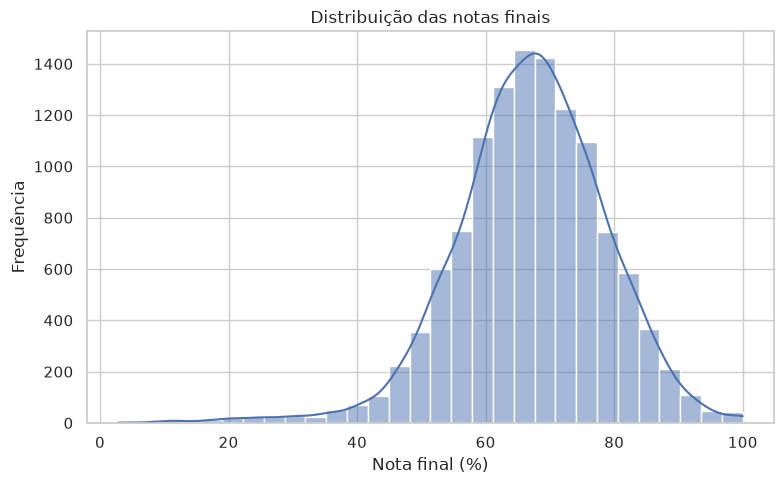

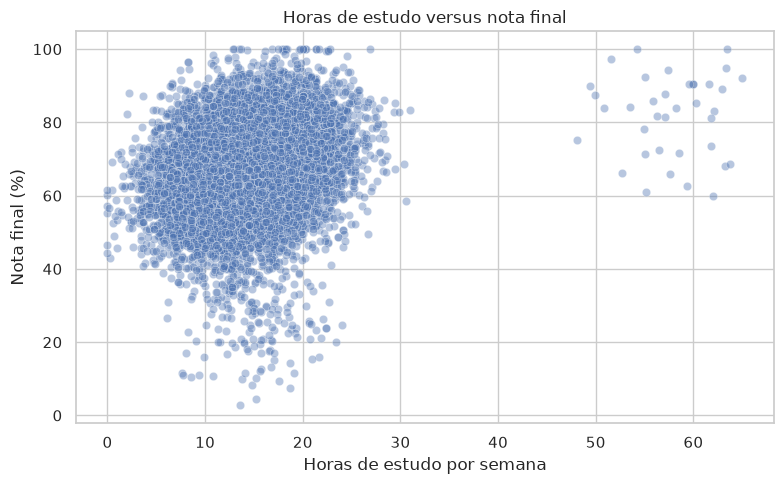

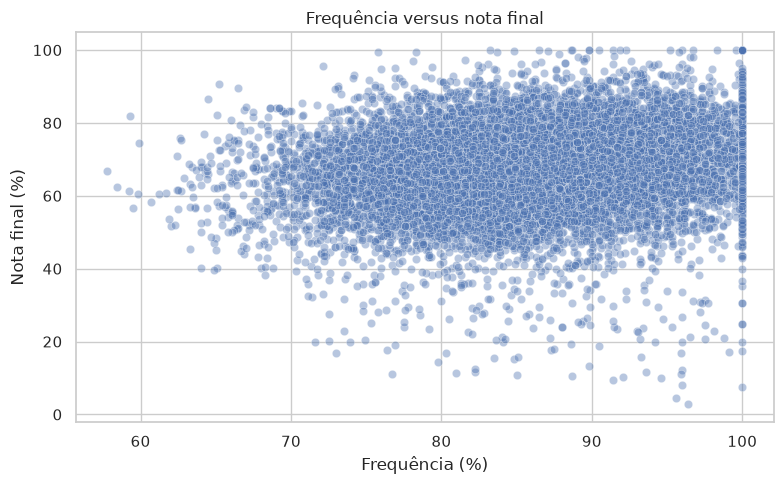

In [7]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="final_grade_pct", bins=30, kde=True)
plt.title("Distribuição das notas finais")
plt.xlabel("Nota final (%)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="study_hours_per_week",
    y="final_grade_pct",
    alpha=0.4
)
plt.title("Horas de estudo versus nota final")
plt.xlabel("Horas de estudo por semana")
plt.ylabel("Nota final (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="attendance_rate_pct",
    y="final_grade_pct",
    alpha=0.4
)
plt.title("Frequência versus nota final")
plt.xlabel("Frequência (%)")
plt.ylabel("Nota final (%)")
plt.tight_layout()
plt.show()

### Correlations

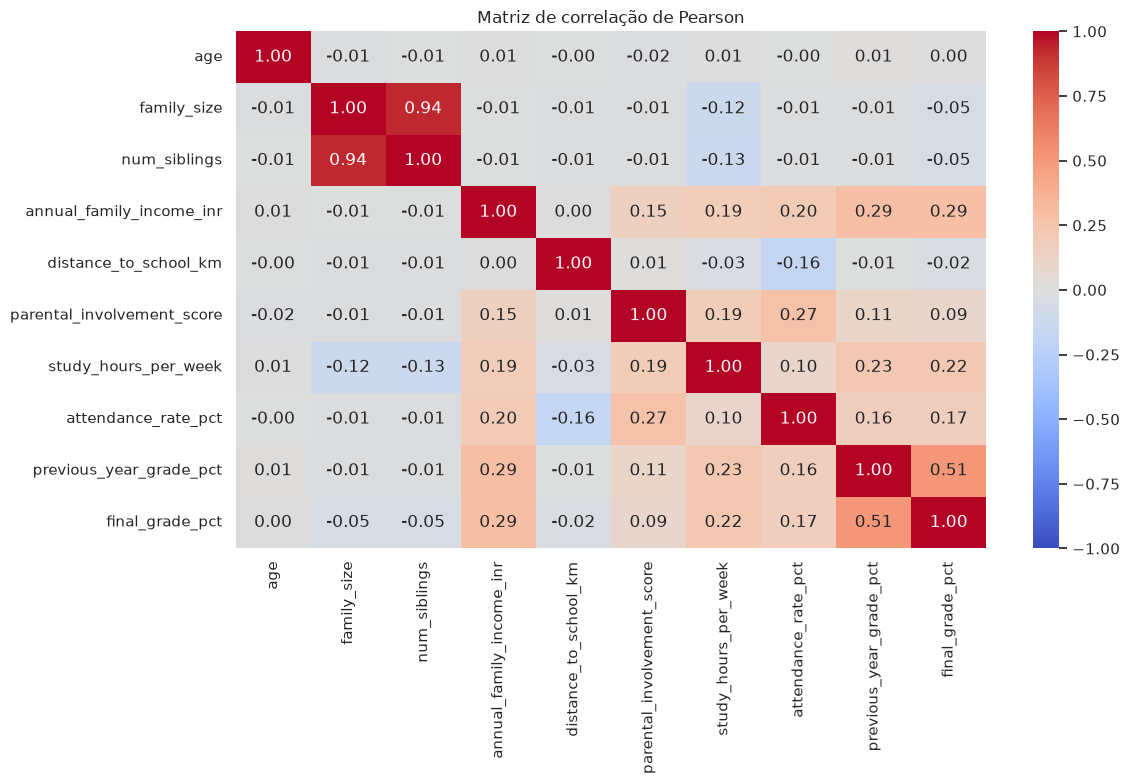

In [8]:

numeric_cols = [
    "age",
    "family_size",
    "num_siblings",
    "annual_family_income_inr",
    "distance_to_school_km",
    "parental_involvement_score",
    "study_hours_per_week",
    "attendance_rate_pct",
    "previous_year_grade_pct",
    "final_grade_pct",
]

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

corr = df[numeric_cols].corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()


del numeric_cols

In [9]:
target_corr = (
    corr["final_grade_pct"]
    .drop("final_grade_pct")
    .sort_values(key=abs, ascending=False)
)

print(target_corr)

previous_year_grade_pct       0.512056
annual_family_income_inr      0.286372
study_hours_per_week          0.223901
attendance_rate_pct           0.165688
parental_involvement_score    0.093439
family_size                  -0.052206
num_siblings                 -0.048261
distance_to_school_km        -0.024759
age                           0.001727
Name: final_grade_pct, dtype: float64


## 2 - Cleaning +  Preprocessing

In [10]:

def delete_unecessary_columns(df):

    return df.drop(columns=['student_id', 'academic_year', 'survey_date'])

def preprocess_data(df):

    df = delete_unecessary_columns(df)


    # Classificação binária: aprovado (1) ou reprovado (0)
    y = (df['final_grade_pct'] >= 70).astype(int)

    X = df.drop(
        columns=[
            'final_grade_pct',
            'grade_class',
            'at_risk_flag'
        ])

    del df

    numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = X.select_dtypes(include=[str]).columns.tolist()

    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_pipeline, numerical_cols),
            ('cat', categorical_pipeline, categorical_cols)
        ])
    
    X_train, X_temp, y_train, y_temp = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.5,
        random_state=42,
        stratify=y_temp
    )

    X_train = preprocessor.fit_transform(X_train)

    X_val = preprocessor.transform(X_val)
    X_test = preprocessor.transform(X_test)

    return X_train, X_val, X_test, y_train, y_val, y_test



In [11]:
X_train, X_val, X_test, y_train, y_val, y_test = preprocess_data(df)

## 3 - Building Model

### Logistic Regression

#### Descrição

#Todo

In [ ]:

class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, num_iterations=1000, alpha=0.01):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.alpha = alpha
        self.w = None
        self.b = None
        self.J_history = []
        self.w_history = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    @staticmethod
    def _compute_cost( X, y, w, b, **argv):

        m, n = X.shape

        loss_sum = 0

        for i in range(m):

            z_wb= 0
            for j in range(n):

                z_wb_ij = w[j] * X[i][j]
                z_wb += z_wb_ij

            z_wb  += b
            f_wb = LogisticRegressionScratch._sigmoid(z_wb)

            # limita a probabilidade antes de calcular os logaritmos, isso evita que o logaritmo receba exatamente 0.
            epsilon = 1e-15
            f_wb = np.clip(f_wb, epsilon, 1 - epsilon)

            loss_sum += -y[i] * np.log(f_wb) - (1 - y[i]) * np.log(1 - f_wb)

        return loss_sum / m

    @staticmethod
    def _compute_gradient( X, y, w, b, **argv):

        m, n= X.shape

        dj_dw= np.zeros(w.shape)
        dj_db= 0

        for i in range(m):

            z_wb= 0

            for j in range(n):

                z_wb_ij = w[j] * X [i][j]
                z_wb += z_wb_ij

            z_wb += b

            f_wb = LogisticRegressionScratch._sigmoid(z_wb)

            dj_db_i = f_wb - y[i]
            dj_db += dj_db_i
            
            for j in range(n):
                dj_dw_ij = (f_wb - y[i])*X[i][j]
                dj_dw[j] += dj_dw_ij
                
                
        dj_dw /= m
        dj_db /= m
        

            
        return dj_db, dj_dw

    @staticmethod
    def _gradient_descent( X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 

        J_history = []
        w_history = []
                    
        for i in range(num_iters):

            dj_db, dj_dw = gradient_function(X, y, w_in, b_in)   

            w_in = w_in - alpha * dj_dw               
            b_in = b_in - alpha * dj_db              
        
            if i<100000:       
                cost =  cost_function(X, y, w_in, b_in)
                J_history.append(cost)

            if i% math.ceil(num_iters/10) == 0 or i == (num_iters-1):
                w_history.append(w_in)
                print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}   ")
            
            
        return w_in, b_in, J_history, w_history 

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)

        initial_w = np.zeros(X.shape[1])
        initial_b = 0.0

        self.w, self.b, self.J_history, self.w_history = self._gradient_descent(
            X=X,
            y=y,
            w_in=initial_w,
            b_in=initial_b,
            cost_function=self._compute_cost,
            gradient_function=self._compute_gradient,
            alpha=self.alpha,
            num_iters=self.num_iterations
        )

        return self

    def predict_proba(self, X):
        if self.w is None:
            raise ValueError("O modelo precisa ser treinado antes da previsão.")

        X = np.asarray(X, dtype=float)

        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)

        return (probabilities >= threshold).astype(int)

In [ ]:
def evolution_graphs(model):
    plt.figure(figsize=(8, 5))
    plt.plot(range(len(model.J_history)), model.J_history, color='blue')
    plt.title("Cost Function over Iterations")
    plt.xlabel("Iterations")
    plt.ylabel("Cost")
    plt.grid()
    plt.tight_layout()
    plt.show()


def results(accuracy, precision, recall, f1_score, name):
    print("-" * 50)
    print(f"Model: {name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1_score:.4f}")


--------------------------------------------------
Model: Logistic Regression (sklearn)
Accuracy: 0.7263
Precision: 0.7227
Recall: 0.7263
F1 Score: 0.7222
Iteration    0: Cost     0.69   
Iteration  100: Cost     0.61   
Iteration  200: Cost     0.58   
Iteration  300: Cost     0.56   
Iteration  400: Cost     0.55   
Iteration  500: Cost     0.55   
Iteration  600: Cost     0.54   
Iteration  700: Cost     0.54   
Iteration  800: Cost     0.54   
Iteration  900: Cost     0.54   
Iteration  999: Cost     0.53   


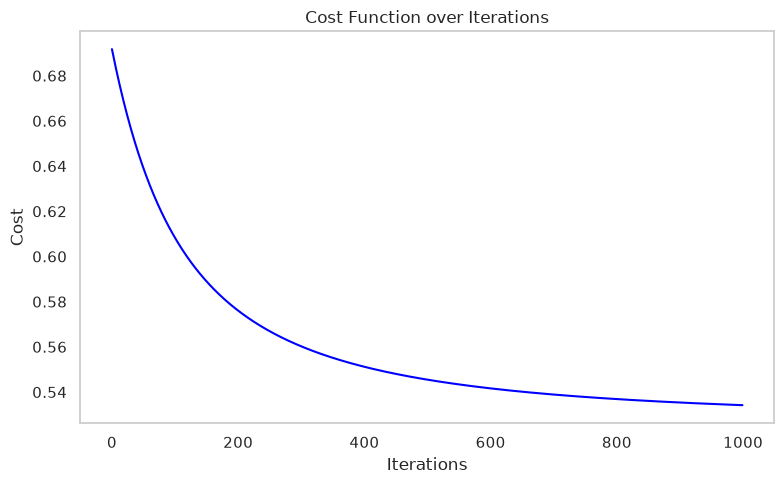

/tmp/ipykernel_100098/428539449.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


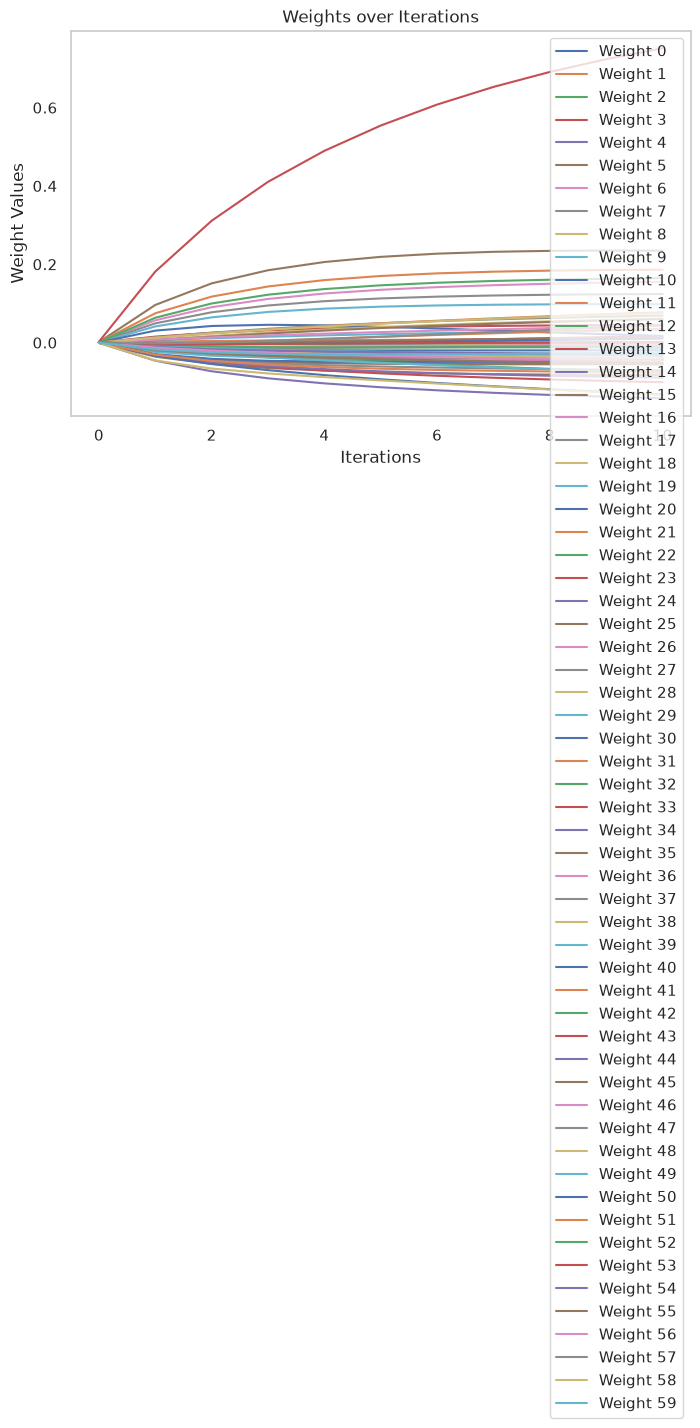

--------------------------------------------------
Model: Logistic Regression (Scratch)
Accuracy: 0.7304
Precision: 0.7274
Recall: 0.7304
F1 Score: 0.7240


In [16]:

candidate_models = {
    "Logistic Regression (sklearn)": LogisticRegression(max_iter=1000),
    "Logistic Regression (Scratch)": LogisticRegressionScratch(learning_rate=0.01, num_iterations=1000, alpha=0.01)
}

for name, model in candidate_models.items():

    model.fit(X_train, y_train)

    val_preds = model.predict(X_val)

    if '(Scratch)' in name : evolution_graphs(model)

    val_acc= accuracy_score(y_val, val_preds)
    val_prec= precision_score(y_val, val_preds, average='weighted', zero_division=0)
    val_rec= recall_score(y_val, val_preds, average='weighted', zero_division=0)
    val_f1= f1_score(y_val, val_preds, average='weighted', zero_division=0) 


    results(val_acc, val_prec, val_rec, val_f1, name)